# Basic Libraries

In [2]:
import numpy as np
import pandas as pd

# Plot library

In [3]:
import matplotlib.pyplot as plt
import plotly.graph_objs as go
import plotly.io as pio


In [4]:
# NLP

In [5]:
%pip install textblob
%pip install wordcloud
import nltk
from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from textblob import Word, TextBlob
from wordcloud import WordCloud  # visualization of words
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# Metrics

In [6]:
from sklearn.model_selection import cross_val_score, GridSearchCV, cross_validate
from sklearn.preprocessing import LabelEncoder

Machine Learning Models

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

#Customize to Remove Warnings and Better Observation

In [8]:
from warnings import filterwarnings
filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [36]:
df = pd.read_csv(r'C:\Users\Shash\OneDrive\Desktop\test(in).csv')
df.head()

,Subject,body,date,from
0,EnronOptions Update!,EnronOptions Announcement\n\n\nWe have updated...,5/10/2010,sally.beck@enron.com
1,(No Subject),"Marc,\n\nUnfortunately, today is not going to ...",7/29/2010,eric.bass@enron.com
2,Phone Screen Interview - Shannon L. Burnham,"When: Wednesday, June 06, 2001 10:00 AM-11:00 ...",7/25/2011,sally.beck@enron.com
3,RE: My new work email,we were thinking papasitos (we can meet somewh...,3/25/2010,johnny.palmer@enron.com
4,Bet,Since you never gave me the $20 for the last t...,5/21/2011,lydia.delgado@enron.com


In [37]:
df.isnull().sum()

Subject    0
body       0
date       0
from       0
dtype: int64

# to put all the characters in a standard

In [43]:
df['body'] = df['body'].str.lower() 

In [39]:
df['body'] = df['body'].str.replace('[^\w\s]', '')

In [41]:
df.head()

,Subject,body,date,from
0,EnronOptions Update!,enronoptions announcement\n\n\nwe have updated...,5/10/2010,sally.beck@enron.com
1,(No Subject),"marc,\n\nunfortunately, today is not going to ...",7/29/2010,eric.bass@enron.com
2,Phone Screen Interview - Shannon L. Burnham,"when: wednesday, june 06, 2001 10:00 am-11:00 ...",7/25/2011,sally.beck@enron.com
3,RE: My new work email,we were thinking papasitos (we can meet somewh...,3/25/2010,johnny.palmer@enron.com
4,Bet,since you never gave me the $20 for the last t...,5/21/2011,lydia.delgado@enron.com


In [46]:
df['Subject'] = df['Subject'].str.lower() 

In [47]:
df['Subject'] = df['Subject'].str.replace('[^\w\s]', '')

In [48]:
df.head()

,Subject,body,date,from
0,enronoptions update!,enronoptions announcement\n\n\nwe have updated...,5/10/2010,sally.beck@enron.com
1,(no subject),"marc,\n\nunfortunately, today is not going to ...",7/29/2010,eric.bass@enron.com
2,phone screen interview - shannon l. burnham,"when: wednesday, june 06, 2001 10:00 am-11:00 ...",7/25/2011,sally.beck@enron.com
3,re: my new work email,we were thinking papasitos (we can meet somewh...,3/25/2010,johnny.palmer@enron.com
4,bet,since you never gave me the $20 for the last t...,5/21/2011,lydia.delgado@enron.com


In [50]:
df['body'] = df['body'].str.replace('\d', '') 
df['Subject'] = df['Subject'].str.replace('\d', '') 

In [51]:
#stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Shash\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [52]:
sw = stopwords.words('english')

In [53]:
df['body'] = df['body'].apply(lambda x: " ".join(x for x in str(x).split() if x not in sw))
df['Subject'] = df['Subject'].apply(lambda x: " ".join(x for x in str(x).split() if x not in sw))

In [68]:
#rarewords
temp_df = pd.Series(' '.join(df['body']).split()).value_counts()
temp_df

please        620
-             605
enron         301
?             282
know          264
             ... 
spice           1
none.           1
booze.          1
never.          1
prominence      1
Name: count, Length: 11486, dtype: int64

In [64]:
drops = temp_df[temp_df <= 1]

In [69]:
df['body'] = df['body'].apply(lambda x: " ".join(x for x in x.split() if x not in drops))

In [ ]:
#lemmanization
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Shash\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Shash\AppData\Roaming\nltk_data...


True

In [71]:
df['body'] = df['body'].apply(lambda x: " ".join([Word(word).lemmatize() for word in x.split()]))

Visualization

In [72]:
tf = df["body"].apply(lambda x: pd.value_counts(x.split(" "))).sum(axis=0).reset_index()
tf.head()

,index,0
0,enronoptions,17.00
1,web,55.00
2,program,42.00
3,site,54.00
4,=01),13.00


In [73]:
tf.columns = ["words", "tf"] 

In [74]:
tf.sort_values("tf", ascending=False)

,words,tf
63,please,620.00
57,-,605.00
155,enron,301.00
726,?,282.00
61,know,268.00
...,...,...
4410,leave-enl-dailyupdate-txt-11787l@estutenws11.e...,2.00
4411,http://www.har.com/search/condo/indexdetail.cf...,2.00
4412,http://www.har.com/search/condo/indexdetail.cf...,2.00
4413,http://www.har.com/search/condo/indexdetail.cf...,2.00


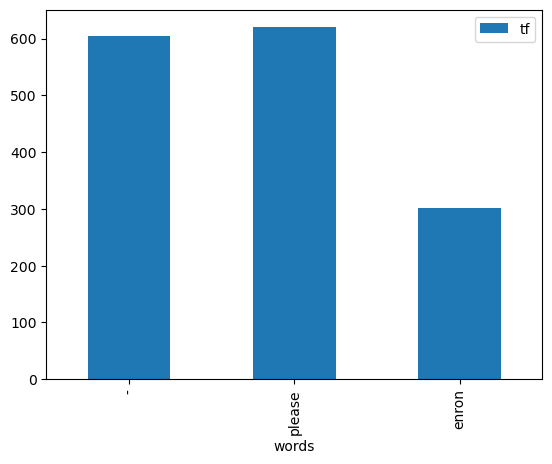

In [75]:
tf[tf["tf"] > 300].plot.bar(x="words", y="tf")
plt.show()

In [77]:
text = " ".join(i for i in df.body) 

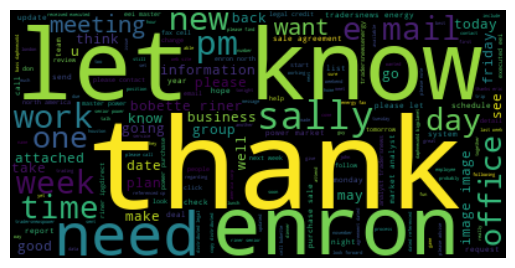

In [78]:
wordcloud = WordCloud().generate(text)
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

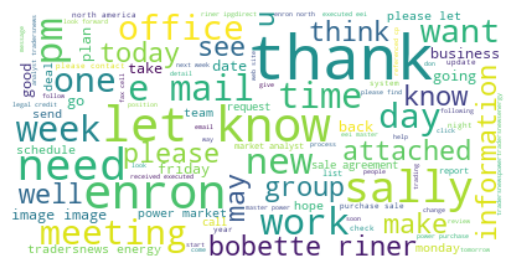

In [79]:
wordcloud = WordCloud(max_font_size=50,
                      max_words=100,
                      background_color="white").generate(text)
plt.figure()
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

In [80]:
df["body"].head()


0    enronoptions announcement updated enronoptions...
1    unfortunately, today going work model mid & ba...
2    when: wednesday, june 06, 2001 10:00 am-11:00 ...
3    thinking papasitos (we meet somewhere closer t...
4    since never gave $20 last time bet cu/texas, f...
Name: body, dtype: object

In [81]:
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Shash\AppData\Roaming\nltk_data...


True

In [83]:
sia = SentimentIntensityAnalyzer()
df["body"][0:10].apply(lambda x: sia.polarity_scores(x)) 

0    {'neg': 0.0, 'neu': 0.886, 'pos': 0.114, 'comp...
1    {'neg': 0.071, 'neu': 0.774, 'pos': 0.155, 'co...
2    {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...
3    {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...
4    {'neg': 0.0, 'neu': 0.917, 'pos': 0.083, 'comp...
5    {'neg': 0.0, 'neu': 0.813, 'pos': 0.187, 'comp...
6    {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...
7    {'neg': 0.065, 'neu': 0.63, 'pos': 0.305, 'com...
8    {'neg': 0.0, 'neu': 0.328, 'pos': 0.672, 'comp...
9    {'neg': 0.0, 'neu': 0.973, 'pos': 0.027, 'comp...
Name: body, dtype: object

In [84]:
df["body"][0:10].apply(lambda x: sia.polarity_scores(x)["compound"])

0   0.82
1   0.42
2   0.00
3   0.00
4   0.25
5   0.32
6   0.00
7   0.84
8   0.80
9   0.20
Name: body, dtype: float64

In [86]:
df["polarity_score"] = df["body"].apply(lambda x: sia.polarity_scores(x)["compound"])

In [87]:
df["body"][0:10].apply(lambda x: "pos" if sia.polarity_scores(x)["compound"] > 0 else "neg")

0    pos
1    pos
2    neg
3    neg
4    pos
5    pos
6    neg
7    pos
8    pos
9    pos
Name: body, dtype: object

In [89]:
rev_pol = pd.concat([df["body"][0:10], df["body"][0:10].apply(lambda x: "pos" if sia.polarity_scores(x)["compound"] > 0 else "neg")], axis=1)
rev_pol.columns = ["body", "Polarity Scores"]
rev_pol

,body,Polarity Scores
0,enronoptions announcement updated enronoptions...,pos
1,"unfortunately, today going work model mid & ba...",pos
2,"when: wednesday, june 06, 2001 10:00 am-11:00 ...",neg
3,thinking papasitos (we meet somewhere closer t...,neg
4,"since never gave $20 last time bet cu/texas, f...",pos
5,"sure, call bank delivers. probably around 6:30...",pos
6,"mgl mgmcc may 31, 2000 posted mgl inventory.xl...",neg
7,please print attachment make sure e:mail addre...,pos
8,please advise interest garvin's experience. th...,pos
9,start time tuesday morning changed breakfast s...,pos


In [90]:
df["sentiment_label"] = df["body"].apply(lambda x: "pos" if sia.polarity_scores(x)["compound"] > 0 else "neg")
df["sentiment_label"].value_counts()

sentiment_label
pos    1545
neg     646
Name: count, dtype: int64

In [91]:
df.groupby("sentiment_label")["Star"].mean()

KeyError: 'Column not found: Star'

In [94]:
import pandas as pd # Assuming df is a DataFrame 
missing_values = df.isnull().sum() 
print(missing_values) 

Subject            0
body               0
date               0
from               0
polarity_score     0
sentiment_label    0
dtype: int64


In [95]:
# Identify duplicates 
duplicates = df.duplicated() # Remove duplicates 
df_no_duplicates = df.drop_duplicates()

In [97]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder() 
df['encoded_column'] = le.fit_transform(df['body'])

In [98]:
df_encoded = pd.get_dummies(df, columns=['body'])